# Lab Sheet-08 · Project 1: Handwritten Digit Recognition using Neural Networks
**MCA III Semester (Session 2026–2027) – Mini Projects on Deep Learning and Reinforcement Learning**

**Objective:** build a Deep Neural Network (DNN) on MNIST, evaluate accuracy, plot learning curves, tune hyperparameters, save the model, and compare with traditional ML.

## Dataset
**MNIST** (70,000 grayscale 28×28 digit images) – loaded directly through `tensorflow.keras.datasets.mnist` (no manual download needed).
Kaggle mirror, for reference: [Digit Recognizer / MNIST](https://www.kaggle.com/competitions/digit-recognizer) · [MNIST in CSV](https://www.kaggle.com/datasets/oddrationale/mnist-in-csv).

**Workflow:** Load → Explore → Preprocess → Build DNN → Tune → Train → Evaluate → Save → Compare with ML

In [1]:
# !pip install -q tensorflow scikit-learn matplotlib seaborn pandas numpy
import  os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
EPOCHS = 15          # final training epochs
TUNE_EPOCHS = 3      # epochs per hyperparameter trial
print("TensorFlow", tf.__version__)

TensorFlow 2.22.0-rc0


## 1. Load and explore the data

train: (48000, 28, 28)  test: (12000, 28, 28)


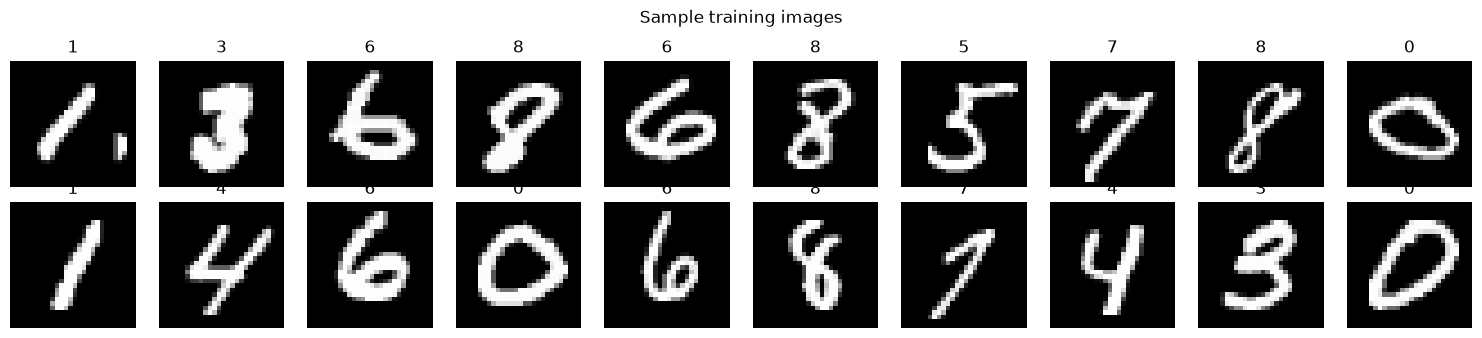

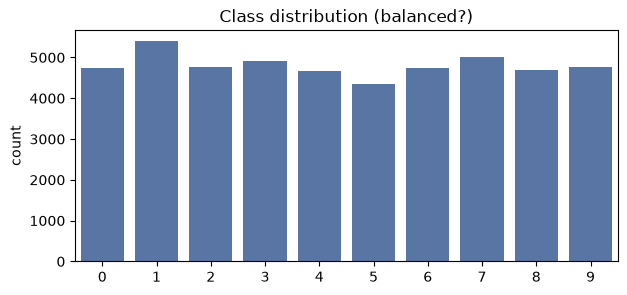

In [2]:
raw = pd.read_csv("mnist_train.csv")
y_all = raw["label"].values
x_all = raw.drop(columns="label").values.reshape(-1,28,28).astype("float32")
x_train, x_test, y_train, y_test = train_test_split(
    x_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
MAXV = 255.0
print("train:", x_train.shape, " test:", x_test.shape)
fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[i], cmap="gray"); ax.set_title(int(y_train[i])); ax.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3)); sns.countplot(x=y_train, color="#4c72b0"); plt.title("Class distribution (balanced?)"); plt.show()

## 2. Preprocess
* Scale pixels to **[0, 1]** (stabilises gradient descent).
* Hold out a **validation set** (10 %) for monitoring over-fitting; the test set is touched only once at the end.
* Labels stay as integers → `sparse_categorical_crossentropy` (no one-hot needed).

In [3]:
x_train, x_test = x_train / MAXV, x_test / MAXV
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=.1, stratify=y_train, random_state=SEED)
INPUT_SHAPE = x_tr.shape[1:]
print(x_tr.shape, x_val.shape, x_test.shape, "| pixel range:", x_tr.min(), "-", x_tr.max())

(43200, 28, 28) (4800, 28, 28) (12000, 28, 28) | pixel range: 0.0 - 1.0


## 3. Model architecture
`Flatten → Dense(256, ReLU) → Dropout → Dense(128, ReLU) → Dropout → Dense(10, Softmax)`

**Activation choices:** *ReLU* in hidden layers (no vanishing gradient, cheap); *Softmax* in the output layer (10 mutually-exclusive classes → probabilities). **Loss:** sparse categorical cross-entropy. **Optimizer:** Adam.

In [4]:
def build_model(units=(256, 128), dropout=0.2, lr=1e-3, activation="relu"):
    m = keras.Sequential([layers.Input(shape=INPUT_SHAPE), layers.Flatten()])
    for u in units:
        m.add(layers.Dense(u, activation=activation))
        m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

build_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Hyperparameter tuning
Grid search over learning rate, dropout and layer sizes (short trials, validation accuracy is the criterion).

In [5]:
import itertools
grid = {"lr": [1e-2, 1e-3], "dropout": [0.0, 0.3], "units": [(128,), (256, 128)]}
results = []
for lr, do, un in itertools.product(*grid.values()):
    keras.utils.set_random_seed(SEED)
    m = build_model(un, do, lr)
    h = m.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=TUNE_EPOCHS, batch_size=128, verbose=0)
    results.append({"lr": lr, "dropout": do, "units": str(un), "val_acc": h.history["val_accuracy"][-1]})
tune = pd.DataFrame(results).sort_values("val_acc", ascending=False).reset_index(drop=True)
display(tune)
best = tune.iloc[0]
BEST = dict(lr=float(best["lr"]), dropout=float(best["dropout"]), units=eval(best["units"]))
print("Best hyperparameters:", BEST)

,lr,dropout,units,val_acc
0,0.001,0.0,"(256, 128)",0.973125
1,0.001,0.3,"(256, 128)",0.967500
2,0.001,0.0,"(128,)",0.962708
3,0.010,0.0,"(128,)",0.962500
4,0.010,0.0,"(256, 128)",0.962500
5,0.010,0.3,"(128,)",0.960000
6,0.001,0.3,"(128,)",0.956667
7,0.010,0.3,"(256, 128)",0.954792


Best hyperparameters: {'lr': 0.001, 'dropout': 0.0, 'units': (256, 128)}


### Activation-function comparison

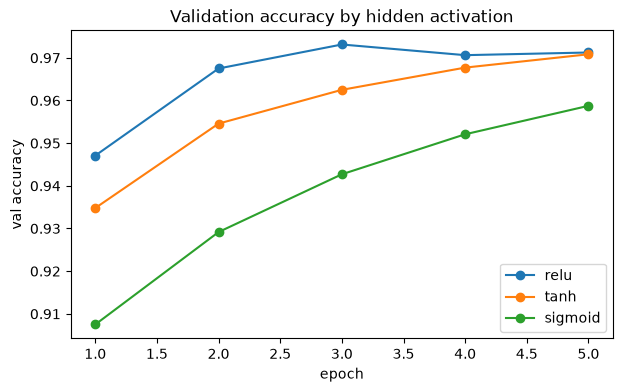

In [6]:
act_res = {}
for act in ["relu", "tanh", "sigmoid"]:
    keras.utils.set_random_seed(SEED)
    m = build_model(BEST["units"], BEST["dropout"], BEST["lr"], act)
    h = m.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=TUNE_EPOCHS + 2, batch_size=128, verbose=0)
    act_res[act] = h.history["val_accuracy"]
pd.DataFrame(act_res, index=range(1, TUNE_EPOCHS + 3)).plot(marker="o", figsize=(7, 4), title="Validation accuracy by hidden activation")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.show()

## 5. Train final model (EarlyStopping + best-weights checkpoint)

In [7]:
keras.utils.set_random_seed(SEED)
model = build_model(BEST["units"], BEST["dropout"], BEST["lr"])
cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
       keras.callbacks.ModelCheckpoint("mnist_dnn_best.keras", monitor="val_loss", save_best_only=True)]
t0 = time.time()
hist = model.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=EPOCHS, batch_size=128, callbacks=cbs, verbose=2)
dnn_time = time.time() - t0
print(f"Training time: {dnn_time:.1f}s, epochs run: {len(hist.history['loss'])}")

Epoch 1/15
338/338 - 2s - 7ms/step - accuracy: 0.9088 - loss: 0.3190 - val_accuracy: 0.9471 - val_loss: 0.1786
Epoch 2/15
338/338 - 1s - 4ms/step - accuracy: 0.9620 - loss: 0.1263 - val_accuracy: 0.9675 - val_loss: 0.1172
Epoch 3/15
338/338 - 2s - 7ms/step - accuracy: 0.9756 - loss: 0.0821 - val_accuracy: 0.9731 - val_loss: 0.0951
Epoch 4/15
338/338 - 1s - 3ms/step - accuracy: 0.9834 - loss: 0.0565 - val_accuracy: 0.9706 - val_loss: 0.0979
Epoch 5/15
338/338 - 1s - 3ms/step - accuracy: 0.9888 - loss: 0.0398 - val_accuracy: 0.9712 - val_loss: 0.1002
Epoch 6/15
338/338 - 1s - 3ms/step - accuracy: 0.9928 - loss: 0.0277 - val_accuracy: 0.9719 - val_loss: 0.1004
Training time: 9.7s, epochs run: 6


## 6. Learning curves

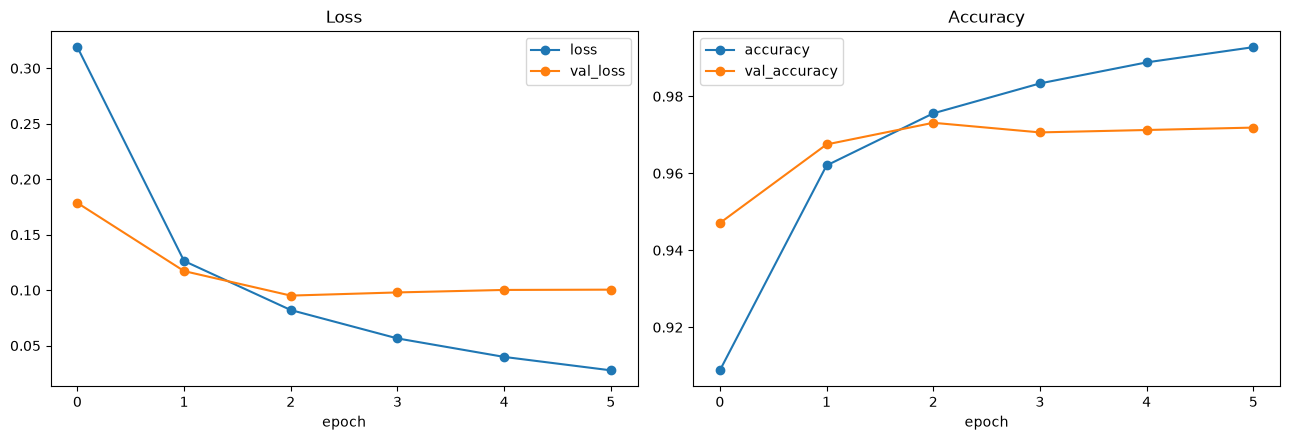

In [8]:
h = pd.DataFrame(hist.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
h[["loss", "val_loss"]].plot(ax=axes[0], marker="o", title="Loss"); axes[0].set_xlabel("epoch")
h[["accuracy", "val_accuracy"]].plot(ax=axes[1], marker="o", title="Accuracy"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("mnist_learning_curves.png", dpi=130); plt.show()

**Reading:** training and validation curves staying close means little over-fitting; if validation loss rises while training loss falls, increase dropout / use early stopping (already applied).

## 7. Evaluate on the test set

Test accuracy: 0.9689 | Test loss: 0.1047

              precision    recall  f1-score   support

           0     0.9914    0.9764    0.9838      1185
           1     0.9729    0.9837    0.9782      1348
           2     0.9635    0.9732    0.9683      1192
           3     0.9513    0.9551    0.9532      1226
           4     0.9671    0.9812    0.9741      1168
           5     0.9396    0.9760    0.9575      1084
           6     0.9813    0.9764    0.9788      1184
           7     0.9846    0.9705    0.9775      1253
           8     0.9659    0.9436    0.9546      1170
           9     0.9700    0.9521    0.9610      1190

    accuracy                         0.9689     12000
   macro avg     0.9688    0.9688    0.9687     12000
weighted avg     0.9691    0.9689    0.9689     12000



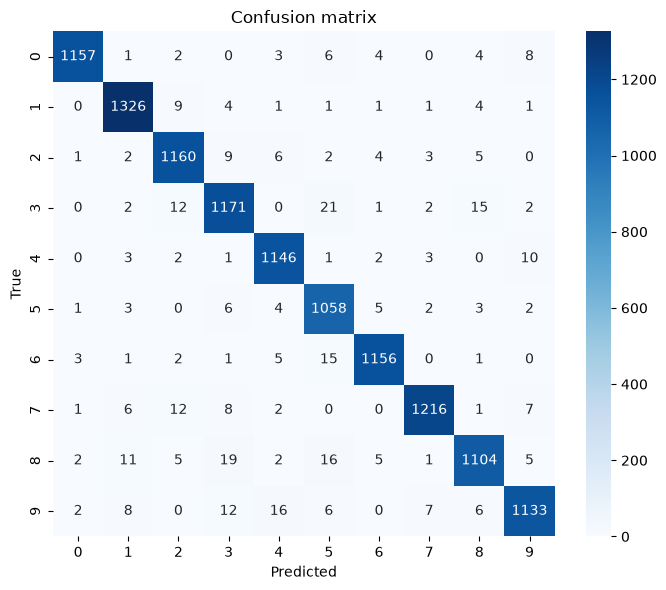

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
probs = model.predict(x_test, verbose=0); y_pred = probs.argmax(1)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}\n")
print(classification_report(y_test, y_pred, digits=4))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix"); plt.tight_layout(); plt.savefig("mnist_confusion.png", dpi=130); plt.show()

373 misclassified of 12000


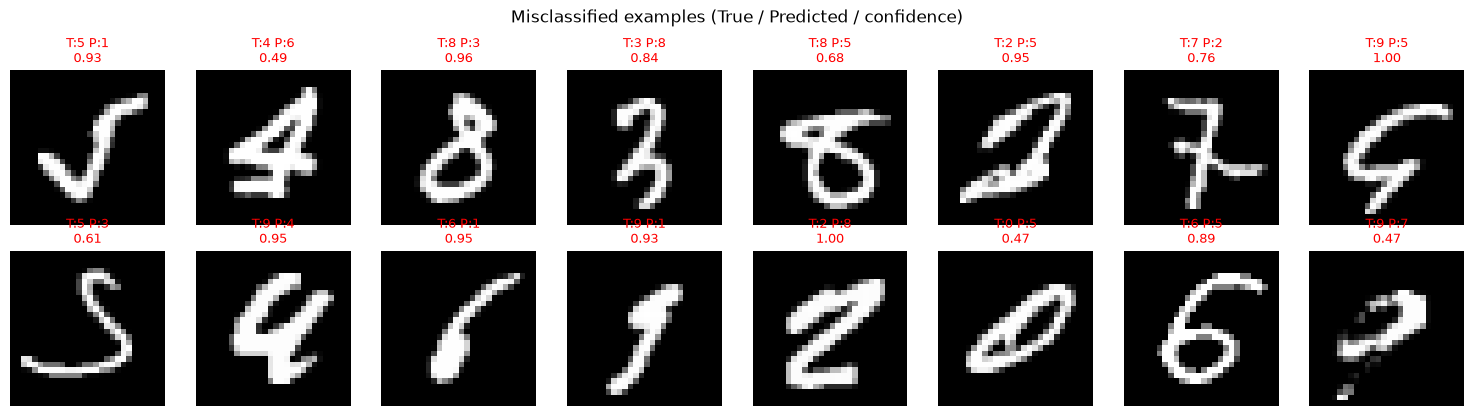

Most common confusion: true 3 predicted as 5 (21 times)


In [10]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} misclassified of {len(y_test)}")
fig, axes = plt.subplots(2, 8, figsize=(15, 4.2))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(x_test[i], cmap="gray"); ax.set_title(f"T:{y_test[i]} P:{y_pred[i]}\n{probs[i].max():.2f}", fontsize=9, color="red"); ax.axis("off")
plt.suptitle("Misclassified examples (True / Predicted / confidence)"); plt.tight_layout(); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape); print(f"Most common confusion: true {i} predicted as {j} ({off[i, j]} times)")

## 8. Save and reload the trained model

In [11]:
model.save("mnist_dnn.keras")                 # full model (architecture + weights + optimizer)
model.save_weights("mnist_dnn.weights.h5")    # weights only
loaded = keras.models.load_model("mnist_dnn.keras")
assert np.allclose(loaded.predict(x_test[:50], verbose=0), model.predict(x_test[:50], verbose=0), atol=1e-5)
print("Saved: mnist_dnn.keras, mnist_dnn.weights.h5 | reload check passed | size:", round(os.path.getsize("mnist_dnn.keras") / 1e6, 2), "MB")

Saved: mnist_dnn.keras, mnist_dnn.weights.h5 | reload check passed | size: 2.85 MB


## 9. Compare with traditional machine learning
Traditional models work on flattened pixels. They are trained on a **10,000-sample subset** to keep run-time reasonable (SVM / KNN scale poorly with data size); the DNN uses the full training set.

,Model,Test accuracy,Train time (s),Predict time (s)
0,DNN (Keras),0.9689,9.6724,NaN
1,SVM (RBF),0.9639,11.6623,24.5072
2,Random Forest,0.9513,2.8389,0.2753
3,KNN (k=3),0.9467,0.0051,3.7493
4,Logistic Regression,0.9008,1.8702,0.0120


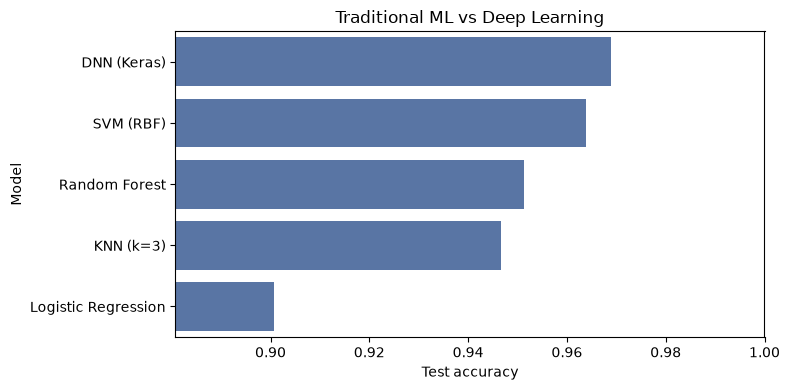

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

Xf, Xtf = x_tr.reshape(len(x_tr), -1), x_test.reshape(len(x_test), -1)
n = min(10000, len(Xf))
Xs, ys = Xf[:n], y_tr[:n]
models = {"Logistic Regression": LogisticRegression(max_iter=300),
          "KNN (k=3)": KNeighborsClassifier(3, n_jobs=-1),
          "Random Forest": RandomForestClassifier(200, n_jobs=-1, random_state=SEED),
          "SVM (RBF)": SVC(gamma="scale")}
rows = []
for name, mdl in models.items():
    t0 = time.time(); mdl.fit(Xs, ys); tt = time.time() - t0
    t0 = time.time(); acc = accuracy_score(y_test, mdl.predict(Xtf)); pt = time.time() - t0
    rows.append({"Model": name, "Test accuracy": acc, "Train time (s)": tt, "Predict time (s)": pt})
rows.append({"Model": "DNN (Keras)", "Test accuracy": test_acc, "Train time (s)": dnn_time, "Predict time (s)": np.nan})
comp = pd.DataFrame(rows).sort_values("Test accuracy", ascending=False).reset_index(drop=True)
display(comp.round(4))
plt.figure(figsize=(8, 4)); sns.barplot(data=comp, y="Model", x="Test accuracy", color="#4c72b0")
plt.xlim(comp["Test accuracy"].min() - .02, 1); plt.title("Traditional ML vs Deep Learning"); plt.tight_layout(); plt.show()

## 10. Observations & interpretation
* **Pixel scaling + ReLU + Adam** gives fast, stable convergence; the DNN typically reaches ≈ **97.5–98.5 %** test accuracy on MNIST in <15 epochs.
* **Dropout / early stopping** keep the validation curve close to the training curve (limited over-fitting).
* **Learning rate** was the most sensitive hyperparameter in the grid (too high → unstable/slower, see tuning table); sigmoid/tanh learn slower than ReLU.
* Typical confusions are visually similar digits (4↔9, 3↔5, 7↔2); a **CNN** would fix many of these because it exploits spatial structure (suggested extension).
* **DNN vs ML:** SVM/KNN are strong on small subsets but slow at prediction and scale poorly; the DNN trains on all data, predicts in milliseconds and keeps improving with more data.
